# 02 - Baselines, 1D-CNN, evaluation and uncertainty


**What this notebook does -**  Trains and evaluates Logistic Regression (baseline), Random Forest and an SVM on 600 summary features, and a 1D-CNN on the raw sequences, each under stratified 10-fold cross-validation and leave-one-subject-out (LOSO). It then adds 95% subject-level bootstrap intervals and paired comparisons, a per-subject check against body measurements, and an error analysis.

**Notes -** The SVM's `C` is chosen by 3-fold cross-validation inside each training set only (the inner folds are not subject-aware, which is a small limitation). Random seed 42.

## Setup

In [ ]:
import os
if not os.path.exists("/content/project"):
    !git clone https://github.com/BHAGI-99/CS5998-Capstone-Project-P.B.W.Nanayakkara-268472T.git /content/project
%cd /content/project
!git pull
!python src/download_data.py
!python src/segment.py

/content/project
Already up to date.
Already downloaded: data/raw/Smart-Sleeve-Dataset
X (2520, 208, 200) uint16 | classes: 18 | subjects: 14
truncated segments: 123


## Classical models on summary features
Mean, standard deviation and maximum of each of the 200 sensors over a trial's true frames (600 features).

In [ ]:
import numpy as np, pandas as pd, time
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, LeaveOneGroupOut, cross_val_predict, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

SEED = 42; P = Path("data/processed"); R = Path("results"); R.mkdir(exist_ok=True)
X = np.load(P/"X.npy").astype(np.float32) / 4095.0          # sensor range is 0-4095
y = np.load(P/"y.npy"); subj = np.load(P/"subject.npy"); L = np.minimum(np.load(P/"lengths.npy"), 208)

# 600 summary features per trial: mean, std and max of each of the 200 sensors over the trial's true frames
F = np.array([np.concatenate([X[i, :L[i]].mean(0), X[i, :L[i]].std(0), X[i, :L[i]].max(0)]) for i in range(len(X))])
print("feature table:", F.shape)

models = {
  "lr":  ("Logistic Regression", make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))),
  "rf":  ("Random Forest", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)),
  # SVM: C is chosen by 3-fold CV inside each training set only (never on the test fold)
  "svm": ("SVM (RBF, C tuned)", GridSearchCV(make_pipeline(StandardScaler(), SVC(gamma="scale")), {"svc__C": [1, 10, 100]}, cv=3, n_jobs=-1)),
}
cv10 = StratifiedKFold(10, shuffle=True, random_state=SEED)
rows, store = [], {}
for key, (name, m) in models.items():
    for proto, tag, cv, groups in [("10-fold", "10fold", cv10, None), ("LOSO", "loso", LeaveOneGroupOut(), subj)]:
        t = time.time(); p = cross_val_predict(m, F, y, cv=cv, groups=groups); store[f"{key}_{tag}"] = p
        rows.append([name, proto, round(accuracy_score(y, p), 4), round(f1_score(y, p, average="macro"), 4)])
        print(f"{name:22s} {proto:8s} acc={rows[-1][2]:.4f}  macroF1={rows[-1][3]:.4f}  ({time.time()-t:.0f}s)")
pd.DataFrame(rows, columns=["model", "protocol", "accuracy", "macro_f1"]).to_csv(R/"baselines.csv", index=False)
np.savez(R/"baseline_preds.npz", **store)

feature table: (2520, 600)
Logistic Regression    10-fold  acc=0.6861  macroF1=0.6867  (41s)
Logistic Regression    LOSO     acc=0.5933  macroF1=0.5931  (58s)
Random Forest          10-fold  acc=0.7433  macroF1=0.7398  (39s)
Random Forest          LOSO     acc=0.6651  macroF1=0.6600  (55s)
SVM (RBF, C tuned)     10-fold  acc=0.7722  macroF1=0.7736  (135s)
SVM (RBF, C tuned)     LOSO     acc=0.6639  macroF1=0.6664  (198s)


## 1D-CNN, 10-fold cross-validation
Raw 208 x 200 sequences; validation split for early stopping is taken from the training part only.

In [ ]:
import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, tensorflow as tf, time
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, f1_score
from tensorflow.keras import layers

SEED = 42
def set_seed(s=SEED):
    np.random.seed(s); tf.random.set_seed(s); tf.keras.utils.set_random_seed(s)
set_seed()
P = Path("data/processed")
X = np.load(P/"X.npy").astype(np.float32) / 4095.0      # sensor range is 0-4095
y = np.load(P/"y.npy")

def build_cnn(seq_len=208, n_feat=200, n_classes=18):
    inp = tf.keras.Input(shape=(seq_len, n_feat))
    x = layers.Conv1D(64, 5, padding="same")(inp);  x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.Conv1D(128, 5, padding="same")(x);   x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.Conv1D(128, 3, padding="same", name="last_conv")(x); x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.GlobalAveragePooling1D()(x)               # needed later for CAM
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    m = tf.keras.Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def train_predict(tr, te, max_epochs=60):
    set_seed()
    tr_in, va = train_test_split(tr, test_size=0.1, stratify=y[tr], random_state=SEED)   # validation comes from the training part only
    m = build_cnn()
    es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
    h = m.fit(X[tr_in], y[tr_in], validation_data=(X[va], y[va]), epochs=max_epochs, batch_size=32, callbacks=[es], verbose=0)
    return m.predict(X[te], verbose=0).argmax(1), len(h.history["loss"])

cv = StratifiedKFold(10, shuffle=True, random_state=SEED)
preds = np.zeros(len(y), dtype=int); rows = []
for k, (tr, te) in enumerate(cv.split(X, y), 1):
    t = time.time()
    p, ep = train_predict(tr, te); preds[te] = p
    acc = accuracy_score(y[te], p); rows.append([k, acc, ep])
    print(f"fold {k:2d}: acc={acc:.4f}  epochs={ep}  ({time.time()-t:.0f}s)")

print(f"\nCNN 10-fold: acc={accuracy_score(y, preds):.4f}  macroF1={f1_score(y, preds, average='macro'):.4f}")
Path("results").mkdir(exist_ok=True)
pd.DataFrame(rows, columns=["fold", "accuracy", "epochs"]).to_csv("results/cnn_10fold_folds.csv", index=False)
np.save("results/cnn_10fold_preds.npy", preds)

fold  1: acc=0.7103  epochs=19  (40s)
fold  2: acc=0.6905  epochs=21  (21s)


fold  3: acc=0.7500  epochs=22  (21s)


fold  4: acc=0.7262  epochs=22  (22s)
fold  5: acc=0.7262  epochs=26  (24s)
fold  6: acc=0.7619  epochs=18  (20s)
fold  7: acc=0.7659  epochs=21  (21s)
fold  8: acc=0.7460  epochs=20  (21s)
fold  9: acc=0.7698  epochs=19  (20s)
fold 10: acc=0.7183  epochs=18  (19s)

CNN 10-fold: acc=0.7365  macroF1=0.7373


## 1D-CNN, leave-one-subject-out

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
held-out subject  1: acc=0.6778  epochs=21  (36s)
held-out subject  2: acc=0.6111  epochs=22  (22s)
held-out subject  3: acc=0.7333  epochs=25  (24s)
held-out subject  4: acc=0.5944  epochs=18  (20s)
held-out subject  5: acc=0.6278  epochs=21  (21s)
held-out subject  6: acc=0.5056  epochs=20  (21s)
held-out subject  7: acc=0.7944  epochs=20  (23s)
held-out subject  8: acc=0.6167  epochs=20  (20s)
held-out subject  9: acc=0.7056  epochs=19  (21s)
held-out subject 10: acc=0.8667  epochs=20  (24s)
held-out subject 11: acc=0.5389  epochs=18  (19s)
held-out subject 12: acc=0.4889  epochs=20  (20s)
held-out subject 13: acc=0.6278  epochs=18  (20s)
held-out subject 14: acc=0.6722  epochs=20  (21s)

CNN LOSO: acc=0.6472  macroF1=0.6453
per-subject accuracy: mean=0.647  min=0.489  max=0.867


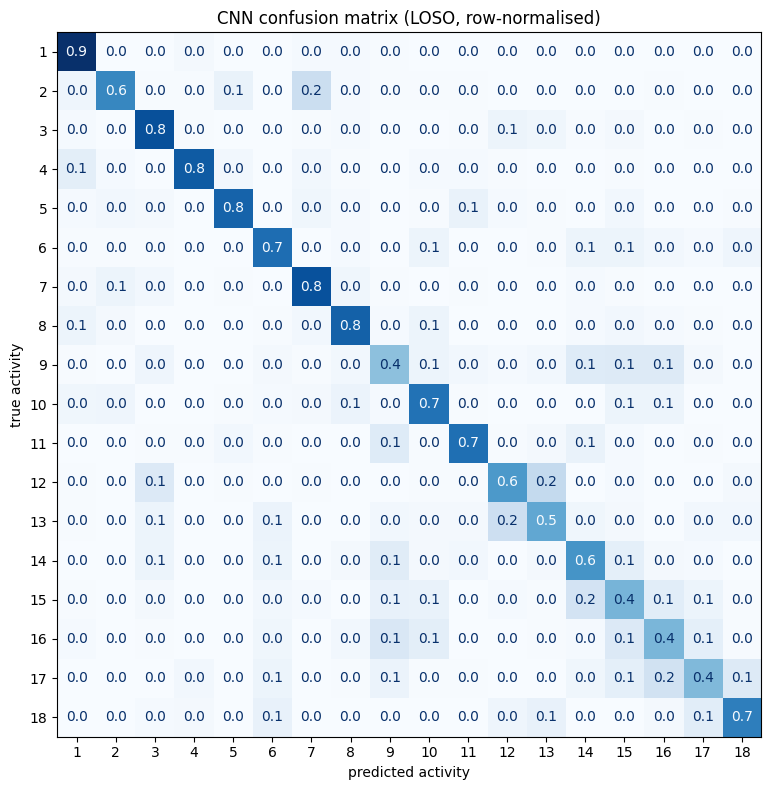

In [ ]:
import os; os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, tensorflow as tf, time
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import LeaveOneGroupOut, train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras import layers

SEED = 42
def set_seed(s=SEED):
    np.random.seed(s); tf.random.set_seed(s); tf.keras.utils.set_random_seed(s)
set_seed()
P = Path("data/processed"); R = Path("results"); (R/"figures").mkdir(parents=True, exist_ok=True)
X = np.load(P/"X.npy").astype(np.float32) / 4095.0      # sensor range is 0-4095
y = np.load(P/"y.npy"); subj = np.load(P/"subject.npy")
print("GPU:", tf.config.list_physical_devices("GPU"))

def build_cnn(seq_len=208, n_feat=200, n_classes=18):
    inp = tf.keras.Input(shape=(seq_len, n_feat))
    x = layers.Conv1D(64, 5, padding="same")(inp);  x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.Conv1D(128, 5, padding="same")(x);   x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.Conv1D(128, 3, padding="same", name="last_conv")(x); x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    m = tf.keras.Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def train_predict(tr, te, max_epochs=60):
    set_seed()
    tr_in, va = train_test_split(tr, test_size=0.1, stratify=y[tr], random_state=SEED)   # validation comes from the training part only
    m = build_cnn()
    es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
    h = m.fit(X[tr_in], y[tr_in], validation_data=(X[va], y[va]), epochs=max_epochs, batch_size=32, callbacks=[es], verbose=0)
    return m.predict(X[te], verbose=0).argmax(1), len(h.history["loss"])

# Leave-one-subject-out: train on 13 people, test on the 14th, repeat for everyone
preds = np.full(len(y), -1); rows = []
for k, (tr, te) in enumerate(LeaveOneGroupOut().split(X, y, groups=subj), 1):
    t = time.time(); p, ep = train_predict(tr, te); preds[te] = p
    acc = accuracy_score(y[te], p); rows.append([int(subj[te][0]), round(acc, 4), ep])
    print(f"held-out subject {int(subj[te][0]):2d}: acc={acc:.4f}  epochs={ep}  ({time.time()-t:.0f}s)")

# Summary and saving
print(f"\nCNN LOSO: acc={accuracy_score(y, preds):.4f}  macroF1={f1_score(y, preds, average='macro'):.4f}")
df = pd.DataFrame(rows, columns=["held_out_subject", "accuracy", "epochs"])
print(f"per-subject accuracy: mean={df.accuracy.mean():.3f}  min={df.accuracy.min():.3f}  max={df.accuracy.max():.3f}")
df.to_csv(R/"cnn_loso_per_subject.csv", index=False); np.save(R/"cnn_loso_preds.npy", preds)

cm = confusion_matrix(y, preds, labels=range(18), normalize="true")
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=range(1, 19)).plot(ax=ax, cmap="Blues", colorbar=False, values_format=".1f")
ax.set(title="CNN confusion matrix (LOSO, row-normalised)", xlabel="predicted activity", ylabel="true activity")
plt.tight_layout(); plt.savefig(R/"figures"/"cnn_loso_confusion.png", dpi=120); plt.show()

## Uncertainty: 95% intervals and paired differences
Trials of one person are not independent, so the 14 subjects are resampled with replacement (5,000 resamples).

In [ ]:
import numpy as np, pandas as pd
from pathlib import Path
R = Path("results"); y = np.load("data/processed/y.npy"); subj = np.load("data/processed/subject.npy")
B = np.load(R/"baseline_preds.npz")
NAMES = {"lr": "Logistic Regression", "rf": "Random Forest", "svm": "SVM (RBF, C tuned)", "cnn": "1D-CNN"}
preds = {"10-fold": {"lr": B["lr_10fold"], "rf": B["rf_10fold"], "svm": B["svm_10fold"], "cnn": np.load(R/"cnn_10fold_preds.npy")},
         "LOSO":    {"lr": B["lr_loso"],   "rf": B["rf_loso"],   "svm": B["svm_loso"],   "cnn": np.load(R/"cnn_loso_preds.npy")}}

# Cluster bootstrap over SUBJECTS (trials of one person are not independent): resample the 14 subjects with replacement
S = np.unique(subj); n_boot = 5000; rng = np.random.default_rng(42)
idx = rng.integers(0, len(S), size=(n_boot, len(S))); cnt = np.array([(subj == s).sum() for s in S])
def boot(correct): return correct[idx].sum(1) / cnt[idx].sum(1)          # accuracy of each bootstrap resample
corr = {pr: {k: np.array([(p[subj == s] == y[subj == s]).sum() for s in S]) for k, p in d.items()} for pr, d in preds.items()}

rows, drows = [], []
for pr in preds:
    for k in NAMES:
        b = boot(corr[pr][k]); rows.append([pr, NAMES[k], (preds[pr][k] == y).mean(), *np.percentile(b, [2.5, 97.5])])
    for a, c in [("rf", "lr"), ("svm", "rf"), ("cnn", "rf"), ("cnn", "svm"), ("svm", "lr")]:
        d = boot(corr[pr][a]) - boot(corr[pr][c]); lo, hi = np.percentile(d, [2.5, 97.5])
        drows.append([pr, f"{NAMES[a]} minus {NAMES[c]}", (preds[pr][a] == y).mean() - (preds[pr][c] == y).mean(), lo, hi, (d > 0).mean()])
ci = pd.DataFrame(rows, columns=["protocol", "model", "accuracy", "ci95_low", "ci95_high"]).round(4)
dd = pd.DataFrame(drows, columns=["protocol", "comparison", "accuracy_difference", "ci95_low", "ci95_high", "share_of_resamples_above_0"]).round(4)
print("Accuracy with 95% subject-level bootstrap intervals\n", ci.to_string(index=False))
print("\nPaired differences (an interval that excludes 0 = a clear difference)\n", dd.to_string(index=False))
ci.to_csv(R/"model_comparison_ci.csv", index=False); dd.to_csv(R/"paired_differences_ci.csv", index=False)

Accuracy with 95% subject-level bootstrap intervals
 protocol               model  accuracy  ci95_low  ci95_high
 10-fold Logistic Regression    0.6861    0.6409     0.7313
 10-fold       Random Forest    0.7433    0.6893     0.7968
 10-fold  SVM (RBF, C tuned)    0.7722    0.7135     0.8278
 10-fold              1D-CNN    0.7365    0.6889     0.7818
    LOSO Logistic Regression    0.5933    0.5357     0.6504
    LOSO       Random Forest    0.6651    0.5980     0.7321
    LOSO  SVM (RBF, C tuned)    0.6639    0.5984     0.7286
    LOSO              1D-CNN    0.6472    0.5944     0.7036

Paired differences (an interval that excludes 0 = a clear difference)
 protocol                                   comparison  accuracy_difference  ci95_low  ci95_high  share_of_resamples_above_0
 10-fold      Random Forest minus Logistic Regression               0.0571    0.0357     0.0770                      1.0000
 10-fold       SVM (RBF, C tuned) minus Random Forest               0.0290    0.0083   

## Per-subject accuracy against body measurements
Exploratory only: 14 subjects, no multiple-testing correction.

Per-subject LOSO accuracy and body measurements
          Random Forest    SVM  1D-CNN  arm_length_cm  forearm_length_cm  biceps_circumference_cm
subject                                                                                         
1                0.789  0.789   0.678             51                 26                       30
2                0.500  0.567   0.611             49                 24                       25
3                0.783  0.739   0.733             49                 23                       27
4                0.617  0.633   0.594             55                 27                       32
5                0.711  0.706   0.628             48                 23                       22
6                0.439  0.472   0.506             54                 26                       26
7                0.783  0.806   0.794             55                 27                       28
8                0.622  0.622   0.617             54                 28       

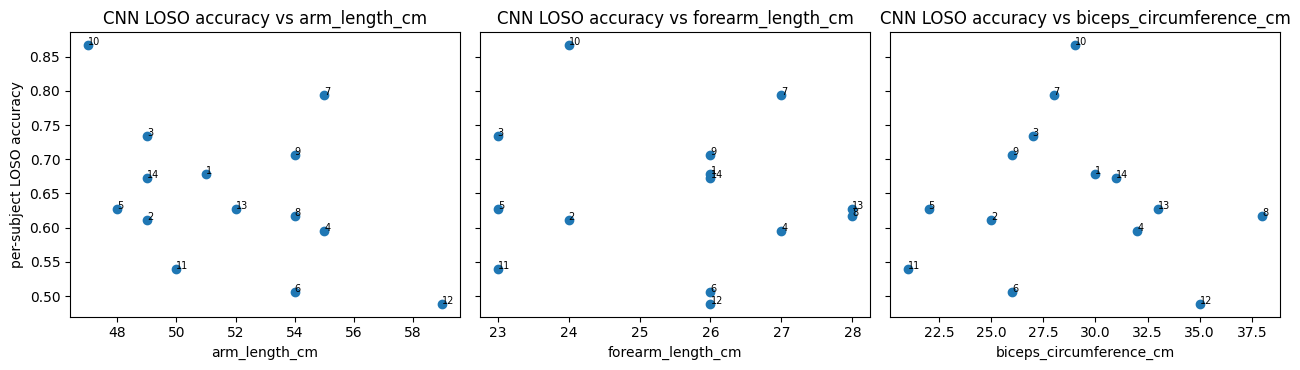

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr
R = Path("results"); (R/"figures").mkdir(parents=True, exist_ok=True)
y = np.load("data/processed/y.npy"); subj = np.load("data/processed/subject.npy"); B = np.load(R/"baseline_preds.npz")
loso = {"Random Forest": B["rf_loso"], "SVM": B["svm_loso"], "1D-CNN": np.load(R/"cnn_loso_preds.npy")}
S = np.arange(1, 15)
acc = pd.DataFrame({m: [(p[subj == s] == y[subj == s]).mean() for s in S] for m, p in loso.items()}, index=S); acc.index.name = "subject"

a = pd.read_excel("data/raw/Smart-Sleeve-Dataset/anthropometric characteristics of subjects.xlsx", index_col=0)
a.index = a.index.astype(str).str.extract(r"(\d+)")[0].astype(int); a.columns = ["arm_length_cm", "forearm_length_cm", "biceps_circumference_cm"]
tab = acc.join(a); print("Per-subject LOSO accuracy and body measurements\n", tab.round(3).to_string())

rows = []
for m in loso:
    for c in a.columns:
        rho, p = spearmanr(tab[m], tab[c]); rows.append([m, c, round(rho, 2), round(p, 3)])
res = pd.DataFrame(rows, columns=["model", "measurement", "spearman_rho", "p_value"]); print("\nSpearman correlation (n = 14 subjects; exploratory, no multiple-testing correction)\n", res.to_string(index=False))
tab.round(4).to_csv(R/"subject_accuracy_vs_anthropometrics.csv")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for k, c in enumerate(a.columns):
    ax[k].scatter(tab[c], tab["1D-CNN"]); ax[k].set(xlabel=c, title=f"CNN LOSO accuracy vs {c}")
    for s in S: ax[k].annotate(str(s), (tab.loc[s, c], tab.loc[s, "1D-CNN"]), fontsize=7)
ax[0].set_ylabel("per-subject LOSO accuracy"); plt.tight_layout(); plt.savefig(R/"figures"/"subject_accuracy_vs_body.png", dpi=120); plt.show()

## Error analysis
Per-activity recall for a new person, and the most confused activity pairs.

Per-activity recall under LOSO
                                     Random Forest   SVM  1D-CNN
1. Stand                                     0.94  0.96    0.94
2. Fold arms                                 0.60  0.71    0.63
3. Think                                     0.86  0.74    0.83
4. Side against the wall                     0.86  0.77    0.79
5. Back against the wall                     0.84  0.71    0.76
6. Arm on the baffle                         0.76  0.90    0.72
7. Hug a doll                                0.74  0.72    0.82
8. Carry a box                               0.85  0.76    0.76
9. Lean forward at work                      0.42  0.48    0.39
10. Lean back at work                        0.75  0.58    0.70
11. Sleep on the table                       0.74  0.69    0.71
12. Hold cheeks                              0.44  0.64    0.56
13. Play mobile phone                        0.50  0.51    0.50
14. Write with a hunchback                   0.56  0.59    0.58
15. Writ

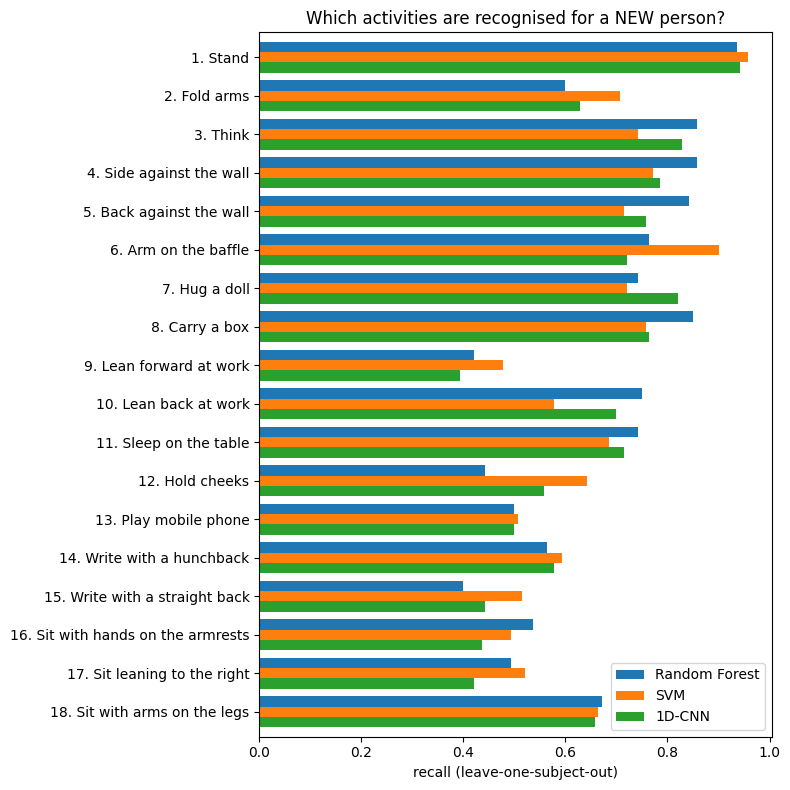


Most confused activity pairs (1D-CNN, LOSO)
  activity_a                         name_a  activity_b                         name_b  confusion_rate
         12                    Hold cheeks          13              Play mobile phone           0.221
          9           Lean forward at work          16 Sit with hands on the armrests           0.132
         16 Sit with hands on the armrests          17       Sit leaning to the right           0.132
          2                      Fold arms           7                     Hug a doll           0.129
         14         Write with a hunchback          15     Write with a straight back           0.129
         15     Write with a straight back          16 Sit with hands on the armrests           0.114
          9           Lean forward at work          14         Write with a hunchback           0.111
         17       Sit leaning to the right          18      Sit with arms on the legs           0.111
          9           Lean forward a

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import confusion_matrix
from src.common import ACTIVITIES
R = Path("results"); y = np.load("data/processed/y.npy"); B = np.load(R/"baseline_preds.npz")
loso = {"Random Forest": B["rf_loso"], "SVM": B["svm_loso"], "1D-CNN": np.load(R/"cnn_loso_preds.npy")}
recall = pd.DataFrame({m: [(p[y == c] == c).mean() for c in range(18)] for m, p in loso.items()}, index=[f"{c+1}. {ACTIVITIES[c]}" for c in range(18)])
print("Per-activity recall under LOSO\n", recall.round(2).to_string())
ax = recall.plot.barh(figsize=(8, 8), width=0.8); ax.invert_yaxis(); ax.set(xlabel="recall (leave-one-subject-out)", title="Which activities are recognised for a NEW person?")
plt.tight_layout(); plt.savefig(R/"figures"/"per_class_recall_loso.png", dpi=120); plt.show()

cm = confusion_matrix(y, loso["1D-CNN"], labels=range(18)).astype(float); cm /= cm.sum(1, keepdims=True); conf = (cm + cm.T) / 2   # symmetric confusion rate
iu = np.triu_indices(18, 1); order = np.argsort(-conf[iu])[:10]
top = pd.DataFrame([[iu[0][k] + 1, ACTIVITIES[iu[0][k]], iu[1][k] + 1, ACTIVITIES[iu[1][k]], round(conf[iu][k], 3)] for k in order],
                   columns=["activity_a", "name_a", "activity_b", "name_b", "confusion_rate"])
print("\nMost confused activity pairs (1D-CNN, LOSO)\n", top.to_string(index=False)); top.to_csv(R/"top_confused_pairs.csv", index=False)

## Self-check and download

In [ ]:
import pandas as pd
from pathlib import Path
R = Path("results")
need = ["baselines.csv", "baseline_preds.npz", "cnn_10fold_folds.csv", "cnn_10fold_preds.npy", "cnn_loso_per_subject.csv", "cnn_loso_preds.npy",
        "model_comparison_ci.csv", "paired_differences_ci.csv", "subject_accuracy_vs_anthropometrics.csv", "top_confused_pairs.csv"]
missing = [f for f in need if not (R/f).exists()]
b = pd.read_csv(R/"baselines.csv").set_index(["model", "protocol"]).accuracy
ok = {"all result files exist": not missing,
      "Random Forest 10-fold in a sensible range (0.65-0.85)": 0.65 < b[("Random Forest", "10-fold")] < 0.85,
      "SVM 10-fold in a sensible range (0.60-0.90)": 0.60 < b[("SVM (RBF, C tuned)", "10-fold")] < 0.90,
      "LOSO below 10-fold for Random Forest": b[("Random Forest", "LOSO")] < b[("Random Forest", "10-fold")]}
for k, v in ok.items(): print("PASS" if v else "FAIL", "-", k)
if missing: print("missing:", missing)
assert all(ok.values()), "A check failed - read the FAIL lines above"
print("\nNotebook 02 self-check: ALL PASS")

PASS - all result files exist
PASS - Random Forest 10-fold in a sensible range (0.65-0.85)
PASS - SVM 10-fold in a sensible range (0.60-0.90)
PASS - LOSO below 10-fold for Random Forest

Notebook 02 self-check: ALL PASS


In [ ]:
!zip -j results_02.zip results/baselines.csv results/baseline_preds.npz results/cnn_10fold_folds.csv results/cnn_10fold_preds.npy results/cnn_loso_per_subject.csv results/cnn_loso_preds.npy results/model_comparison_ci.csv results/paired_differences_ci.csv results/subject_accuracy_vs_anthropometrics.csv results/top_confused_pairs.csv results/figures/cnn_loso_confusion.png results/figures/per_class_recall_loso.png results/figures/subject_accuracy_vs_body.png
from google.colab import files
files.download("results_02.zip")

  adding: baselines.csv (deflated 41%)
  adding: baseline_preds.npz (deflated 90%)
  adding: cnn_10fold_folds.csv (deflated 49%)
  adding: cnn_10fold_preds.npy (deflated 88%)
  adding: cnn_loso_per_subject.csv (deflated 36%)
  adding: cnn_loso_preds.npy (deflated 88%)
  adding: model_comparison_ci.csv (deflated 44%)
  adding: paired_differences_ci.csv (deflated 60%)
  adding: subject_accuracy_vs_anthropometrics.csv (deflated 49%)
  adding: top_confused_pairs.csv (deflated 58%)
  adding: cnn_loso_confusion.png (deflated 11%)
  adding: per_class_recall_loso.png (deflated 18%)
  adding: subject_accuracy_vs_body.png (deflated 14%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>